# 08 1D CNN

**Goal:** train a 1D convolutional neural network (based on the prof's starter notebook) on the same raw 5 m windows as MiniRocket, with the same road split and metrics.

**Why a CNN:** like MiniRocket it works on the raw signal shape, but instead of using random filters it *learns* its own filters during training.

In [1]:
import sys
print(sys.executable)

import keras
print("keras version:", keras.__version__)

c:\D_DRIVE\Roadscanners\SemesterProjectFall2026\.venv\Scripts\python.exe
keras version: 3.15.1


In [2]:
!"{sys.executable}" -m pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# The raw 5 m windows from 06: (windows, sensors, time steps)
X_raw = np.load("data_features/raw_windows_5m.npy").astype(np.float32)
raw_index = pd.read_csv("data_features/raw_windows_index.csv")

# Keras wants (windows, time steps, sensors), so we swap the last two axes.
# This is the same as channels_first=False in the prof's make_panels.
X_keras = X_raw.transpose(0, 2, 1)

print("X_raw shape:  ", X_raw.shape)
print("X_keras shape:", X_keras.shape)

X_raw shape:   (2729, 7, 100)
X_keras shape: (2729, 100, 7)


In [4]:
test_road = "Iisingintie"

is_test = (raw_index["road"] == test_road).to_numpy()
X_train = X_keras[~is_test]
X_test = X_keras[is_test]
y_train = raw_index["is_bump"].to_numpy()[~is_test]
y_test = raw_index["is_bump"].to_numpy()[is_test]

print("Train:", X_train.shape, " bump share:", round(y_train.mean(), 2))
print("Test: ", X_test.shape, " bump share:", round(y_test.mean(), 2))

Train: (916, 100, 7)  bump share: 0.19
Test:  (1813, 100, 7)  bump share: 0.19


### Model prep: validation split and class weights

In [ ]:
import keras
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Same random start every run.
keras.utils.set_random_seed(42)

# 20% of the training windows become validation windows (used only to decide when to stop training).
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Class weights: bumps are rare, so mistakes on bumps count more.
weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_tr)
class_weights = {0: weights[0], 1: weights[1]}

print("Training:  ", X_tr.shape)
print("Validation:", X_val.shape)
print("Class weights:", class_weights)

Training:   (732, 100, 7)
Validation: (184, 100, 7)
Class weights: {0: np.float64(0.6140939597315436), 1: np.float64(2.6911764705882355)}


### The CNN 

In [6]:
from keras import layers

def make_model(input_shape):
    model = keras.Sequential([
        # Input: one window = 100 time steps x 7 sensors.
        layers.Input(input_shape),

        # Convolution block 1: 64 filters, each looks at 3 neighbouring points at a time.
        layers.Conv1D(filters=64, kernel_size=3, padding="same"),
        layers.BatchNormalization(),
        layers.ReLU(),

        # Convolution block 2
        layers.Conv1D(filters=64, kernel_size=3, padding="same"),
        layers.BatchNormalization(),
        layers.ReLU(),

        # Convolution block 3
        layers.Conv1D(filters=64, kernel_size=3, padding="same"),
        layers.BatchNormalization(),
        layers.ReLU(),

        # Average every filter over the whole window -> 64 numbers per window.
        layers.GlobalAveragePooling1D(),

        # A small normal neural network on top.
        layers.Dense(64, activation="relu"),

        # Output: 2 probabilities (no bump, bump) that add up to 1.
        layers.Dense(2, activation="softmax"),
    ])
    return model

model = make_model(input_shape=X_tr.shape[1:])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 64)        │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 100, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 100, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,170 (121.76 KB)

 Trainable params: 30,786 (120.26 KB)

 Non-trainable params: 384 (1.50 KB)

### Training

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Stop when the validation loss hasn't improved for 12 epochs, and go back to the best epoch.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True
)

# Halve the learning rate when the validation loss hasn't improved for 5 epochs.
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=0.00001, verbose=1
)

history = model.fit(
    X_tr, y_tr,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    class_weight=class_weights,
    shuffle=True
)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.6380 - loss: 0.5969 - val_accuracy: 0.7717 - val_loss: 0.5777 - learning_rate: 5.0000e-04
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8251 - loss: 0.4876 - val_accuracy: 0.8043 - val_loss: 0.5742 - learning_rate: 5.0000e-04
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8306 - loss: 0.4365 - val_accuracy: 0.8641 - val_loss: 0.5231 - learning_rate: 5.0000e-04
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8456 - loss: 0.3938 - val_accuracy: 0.8804 - val_loss: 0.4795 - learning_rate: 5.0000e-04
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8593 - loss: 0.3577 - val_accuracy: 0.8533 - val_loss: 0.4545 - learning_rate: 5.0000e-04
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8648 - loss: 0.3277 - val_accuracy: 0.8533 - val_loss: 0.4318 - learning_rate: 5.0000e-04
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8770

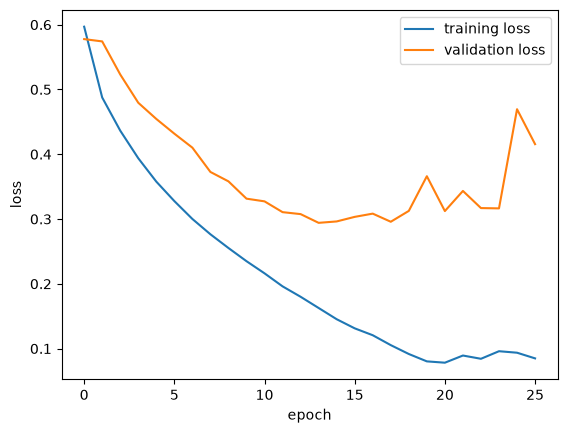

In [8]:
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [9]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# Probabilities for every test window: column 0 = no bump, column 1 = bump.
y_prob = model.predict(X_test, verbose=0)

# The class with the higher probability.
y_pred = np.argmax(y_prob, axis=1)

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob[:, 1]), 2))
print(classification_report(y_test, y_pred, zero_division=0))

ROC-AUC: 0.59
              precision    recall  f1-score   support

           0       0.85      0.82      0.84      1465
           1       0.34      0.38      0.36       348

    accuracy                           0.74      1813
   macro avg       0.59      0.60      0.60      1813
weighted avg       0.75      0.74      0.74      1813



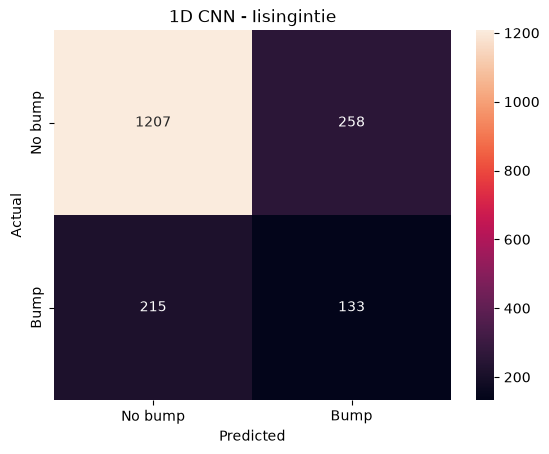

In [10]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["No bump", "Bump"], yticklabels=["No bump", "Bump"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("1D CNN - " + test_road)
plt.show()

### All three roads (leave-one-road-out)

Same steps as above for every road. A **new** model is built in every round, so nothing learned in one round carries over to the next.

In [11]:
from sklearn.metrics import recall_score, precision_score, f1_score

results = []
all_predictions = []

for test_road in raw_index["road"].unique():

    # ---- Split (same as cell 3) ----
    is_test = (raw_index["road"] == test_road).to_numpy()
    X_train = X_keras[~is_test]
    X_test = X_keras[is_test]
    y_train = raw_index["is_bump"].to_numpy()[~is_test]
    y_test = raw_index["is_bump"].to_numpy()[is_test]

    # ---- Validation split and class weights (same as cell 4) ----
    keras.utils.set_random_seed(42)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
    )
    weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_tr)
    class_weights = {0: weights[0], 1: weights[1]}

    # ---- A NEW model for this round (same as cells 5 and 6) ----
    model = make_model(input_shape=X_tr.shape[1:])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True
    )
    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, min_lr=0.00001
    )
    history = model.fit(
        X_tr, y_tr,
        epochs=100,
        batch_size=32,
        validation_data=(X_val, y_val),
        callbacks=[early_stopping, reduce_lr],
        class_weight=class_weights,
        shuffle=True,
        verbose=0
    )

    # ---- Predict the test road (same as cell 8) ----
    y_prob_both = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob_both, axis=1)
    y_prob = y_prob_both[:, 1]

    # ---- Scores for this road (same as in 07) ----
    cm = confusion_matrix(y_test, y_pred)
    results.append({
        "test_road": test_road,
        "recall": recall_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_prob),
        "false_alarms": cm[0, 1],
        "epochs": len(history.history["loss"]),
    })

    # ---- Keep the predictions for this road ----
    pred_table = raw_index[is_test].copy()
    pred_table["pred"] = y_pred
    pred_table["prob"] = y_prob
    all_predictions.append(pred_table)

    print("done:", test_road)

results = pd.DataFrame(results)
print(results.round(2))
print("average f1:", round(results["f1"].mean(), 2), " average auc:", round(results["auc"].mean(), 2))

done: Iisingintie
done: Kaittiaisentie
done: sinetänsalmentie
          test_road  recall  precision    f1   auc  false_alarms  epochs
0       Iisingintie    0.38       0.34  0.36  0.59           258      26
1    Kaittiaisentie    0.77       0.16  0.26  0.80           124      45
2  sinetänsalmentie    0.46       0.78  0.58  0.75            18      41
average f1: 0.4  average auc: 0.71


In [12]:
predictions = pd.concat(all_predictions)
predictions.to_csv("predictions/predictions_cnn.csv", index=False)
print(predictions.shape)

(2729, 6)


### Check: does the result depend on the random seed?

A neural network starts from random numbers, so we repeat the leave-one-road-out run with 5 different seeds.

In [15]:
def train_cnn(test_road, seed, builder=make_model):
    # Split
    is_test = (raw_index["road"] == test_road).to_numpy()
    X_train = X_keras[~is_test]
    X_test = X_keras[is_test]
    y_train = raw_index["is_bump"].to_numpy()[~is_test]
    y_test = raw_index["is_bump"].to_numpy()[is_test]

    # Validation split and class weights, using this seed
    keras.utils.set_random_seed(seed)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=seed, stratify=y_train
    )
    weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_tr)
    class_weights = {0: weights[0], 1: weights[1]}

    # A new model
    model = builder(input_shape=X_tr.shape[1:])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
    reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=0.00001)
    model.fit(
        X_tr, y_tr, epochs=100, batch_size=32,
        validation_data=(X_val, y_val),
        callbacks=[early_stopping, reduce_lr],
        class_weight=class_weights, shuffle=True, verbose=0
    )

    # Predict and score
    y_prob_both = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob_both, axis=1)
    cm = confusion_matrix(y_test, y_pred)
    return {
        "seed": seed,
        "test_road": test_road,
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_prob_both[:, 1]),
        "false_alarms": cm[0, 1],
    }

In [14]:
seed_results = []

for seed in [1, 2, 3, 4, 5]:
    for test_road in raw_index["road"].unique():
        seed_results.append(train_cnn(test_road, seed))
    print("done seed", seed)

seed_results = pd.DataFrame(seed_results)
print(seed_results.groupby("test_road")[["f1", "auc", "false_alarms"]].agg(["mean", "std"]).round(2))

done seed 1
done seed 2
done seed 3
done seed 4
done seed 5
                    f1         auc       false_alarms       
                  mean   std  mean   std         mean    std
test_road                                                   
Iisingintie       0.35  0.01  0.55  0.01        230.8  34.81
Kaittiaisentie    0.29  0.02  0.81  0.01         94.8  12.21
sinetänsalmentie  0.55  0.03  0.73  0.05         18.0   5.34


### Result: 1D CNN (leave-one-road-out, 5 seeds)

| Test road | F1 (mean ± std) | AUC (mean ± std) | False alarms (mean) |
|---|---|---|---|
| Iisingintie | 0.35 ± 0.01 | 0.55 ± 0.01 | 231 |
| Kaittiaisentie | 0.29 ± 0.02 | 0.81 ± 0.01 | 95 |
| sinetänsalmentie | 0.55 ± 0.03 | 0.73 ± 0.05 | 18 |
| **Average** | **0.40** | **0.70** | |

- Results barely depend on the seed (F1 std ≤ 0.03), so they are reliable.
- The CNN overfits fast: validation loss rises from the first epochs, and training stops after 26–45 epochs.
- It is the best model on sinetänsalmentie (F1 0.55 vs RF 0.45), the round with the most training data (2427 windows), and the weakest on Iisingintie, the round with the least (916 windows, AUC close to guessing). → The CNN needs more data than we have.
- Average: F1 0.40, AUC 0.70, slightly below the RF (0.44 / 0.76) and MiniRocket (0.40 / 0.74).

### LSTM (the commented-out version)

An LSTM reads the window step by step (point 1, 2, ..., 100) and keeps a "memory" of what it has seen so far.

In [16]:
def make_lstm(input_shape):
    model = keras.Sequential([
        layers.Input(input_shape),

        # LSTM layer with 64 units: reads the 100 points in order and outputs 64 numbers.
        layers.LSTM(64),

        layers.BatchNormalization(),

        # Randomly switches off 20% of the units during training, against overfitting.
        layers.Dropout(0.2),

        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),

        layers.Dense(2, activation="softmax"),
    ])
    return model

In [17]:
lstm_results = []

for seed in [1, 2, 3]:
    for test_road in raw_index["road"].unique():
        lstm_results.append(train_cnn(test_road, seed, builder=make_lstm))
    print("done seed", seed)

lstm_results = pd.DataFrame(lstm_results)
print(lstm_results.groupby("test_road")[["f1", "auc", "false_alarms"]].agg(["mean", "std"]).round(2))

done seed 1
done seed 2
done seed 3
                    f1         auc       false_alarms       
                  mean   std  mean   std         mean    std
test_road                                                   
Iisingintie       0.34  0.01  0.62  0.03       359.00  66.73
Kaittiaisentie    0.20  0.03  0.82  0.01       176.33  37.07
sinetänsalmentie  0.51  0.00  0.64  0.02        23.67   0.58


### Result: LSTM (Jeremy's commented-out version, leave-one-road-out, 3 seeds)

| Test road | F1 (mean ± std) | AUC (mean ± std) | False alarms (mean) |
|---|---|---|---|
| Iisingintie | 0.34 ± 0.01 | 0.62 ± 0.03 | 359 |
| Kaittiaisentie | 0.20 ± 0.03 | 0.82 ± 0.01 | 176 |
| sinetänsalmentie | 0.51 ± 0.00 | 0.64 ± 0.02 | 24 |
| **Average** | **0.35** | **0.69** | |

- Stable between seeds, but the weakest of the four models, with the most false alarms.
- Reading the window step by step does not help with this amount of data: the LSTM has to learn the bump's order from only a few hundred bump windows.

### Summary of all models (window level, leave-one-road-out)

| Model | Avg F1 | Avg AUC |
|---|---|---|
| Random forest | **0.44** | **0.76** |
| MiniRocket | 0.40 | 0.74 |
| 1D CNN | 0.40 | 0.70 |
| LSTM | 0.35 | 0.69 |

The simplest model with well-designed features is the best overall. The deep learning models only do well when they get the most training data (the CNN on sinetänsalmentie).